In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path

os.environ["AEON_DEPRECATION_WARNING"] = "False"
os.environ["KMP_WARNINGS"] = "off"

import pandas as pd
import matplotlib
from matplotlib import pyplot as plt
import seaborn as sns

from utils import *

sys.path.append("../")
pd.set_option("display.max_rows", 100)

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

%matplotlib inline
%config InlineBackend.figure_formats = {'png', 'retina'}


def load_ucr_query_logs():
    dfs = []

    for ds_name, files in read_UCR_logs().items():
        for cores, file in files.items():
            df = pd.read_csv(file).copy()

            df["querying time"] = df[" querying time"] / 1_000_000
            df["method"] = "UCR SUITE"
            df["base_method"] = "UCR SUITE"
            df["layout"] = "UCR SUITE"
            df["Method"] = "UCR SUITE"

            df["Cores"] = "09" if str(cores) == "9" else str(cores)
            df["split"] = df["Cores"]

            # e.g. logs/UCR_SUITE_logs/ASTRO_9.log -> ASTRO
            name = Path(file).stem
            df["dataset"] = "_".join(name.split("_")[:-1])

            dfs.append(
                df[
                    [
                        "method",
                        "base_method",
                        "layout",
                        "split",
                        "Cores",
                        "dataset",
                        "Method",
                        "querying time",
                    ]
                ]
            )

    columns = [
        "method",
        "base_method",
        "layout",
        "split",
        "Cores",
        "dataset",
        "Method",
        "querying time",
    ]

    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame(columns=columns)


def select_best_ucr_config(df):
    mean_times = (
        df.groupby(["dataset", "Cores"], as_index=False)["querying time"]
        .mean()
    )

    best = mean_times.loc[
        mean_times.groupby("dataset")["querying time"].idxmin()
    ].reset_index(drop=True)

    result = df.merge(
        best[["dataset", "Cores"]],
        on=["dataset", "Cores"],
        how="inner",
    )

    result["selected_config"] = (
        "UCR SUITE "
        + result["Cores"].astype(str)
        + " cores"
    )

    return result
    
# Per-query logs for the two DIDS variants.
DIDS_DEFAULT_ROOT = Path("logs/DIDS_logs")
DIDS_TUNED_ROOT = Path("logs/DIDS_tuned_logs")


# Shows files

In [2]:
# ============================================================
# LOAD iSAX
# ============================================================

"""
configs_isax = [
    "SAX",
    "SOFA+ED",
    "SOFA+EW",
    "SPARTAN+ED",
    "SPARTAN+EW",
]
"""

query_isax_original = load_logs(
    path="trie_logs/segment_scaling/messi/segments-64",
    config_names=[
        "SAX",
    ],
    layout="iSAX",
)

query_isax_sofa = load_logs(
    path="trie_logs/segment_scaling/sofa/segments-64",
    config_names=[
        "SOFA+ED",
        "SOFA+EW",
    ],
    layout="iSAX",
)

query_isax = pd.concat(
    [query_isax_original, query_isax_sofa],
    ignore_index=True,
)

query_isax = add_method_metadata(
    query_isax,
    split="iSAX",
)

display(query_isax)


# ============================================================
# LOAD TRIE
# ============================================================

configs_64dim = [
    "SPARTAN+ED",
    "SPARTAN+EW",
]

query_dims = load_logs(
    path="trie_logs/logs_TRIE_grid_search",
    config_names=["SPARTAN"],
    layout="Trie + GridSearch",
)

query_dims = select_median_query_repeat(
  query_dims,
  queries_per_repeat=100,
)

query_dims = add_method_metadata(
    query_dims,
    split="64dim",
)

query_kmeans = load_logs(
    path="trie_logs/logs_TRIE_64dim_ivf16_ball_avx512_radial_record_parallel_simd-residual-record-only",
    config_names=configs_64dim,
    layout="Trie + 64dim + ivf",
)

query_kmeans = add_method_metadata(
    query_kmeans,
    split="64dim + ivf",
)


# ============================================================
# LOAD DIDS
# ============================================================

query_dids_default = load_dids_logs(
    path=DIDS_DEFAULT_ROOT,
    layout="DIDS",
)
query_dids_default = add_method_metadata(query_dids_default, split="DIDS default")

query_dids_tuned = load_dids_logs(
    path=DIDS_TUNED_ROOT,
    layout="DIDS",
)
query_dids_tuned = add_method_metadata(query_dids_tuned, split="DIDS tuned")

query_dids = query_dids_tuned

if query_dids.empty:
    raise FileNotFoundError(f"No tuned DIDS query results in {DIDS_TUNED_ROOT.resolve()}")
print(f"DIDS tuned: {query_dids_tuned['dataset'].nunique()} datasets")
if query_dids_tuned.empty:
    raise FileNotFoundError(f"No tuned DIDS queries found under {DIDS_TUNED_ROOT.resolve()}")

# ============================================================
# LOAD + SELECT BEST UCR SUITE CONFIGURATION
# ============================================================

ucr_query_times = load_ucr_query_logs()

ucr_query_times["dataset"] = (
    ucr_query_times["dataset"]
    .astype(str)
    .str.strip()
    .str.upper()
)

ucr_best = select_best_ucr_config(ucr_query_times)


# ============================================================
# ALIGN UCR TO MAIN SCHEMA
# ============================================================



# ============================================================
# COMBINE iSAX / TRIE / DIDS
# ============================================================

query_times = pd.concat(
    [
        query_isax,
        query_dims,
        query_kmeans,
        query_dids,
        ucr_best,
    ],
    ignore_index=True,
)

# Normalize all dataset names globally
query_times["dataset"] = (
    query_times["dataset"]
    .astype(str)
    .str.strip()
    .str.upper()
)


# ============================================================
# SELECT BEST iSAX / TRIE / DIDS CONFIGURATIONS
# ============================================================

query_times_best = select_best_query_configs(
    query_times
)


# ============================================================
# LOAD + SELECT BEST FAISS CONFIGURATION
# ============================================================

faiss_query_times = load_faiss_query_logs()

faiss_best = select_best_faiss_config(
    faiss_query_times
)


# ============================================================
# NORMALIZE FAISS TO SAME SCHEMA
# ============================================================

faiss_best = align_columns(
    faiss_best,
    query_times_best.columns,
)


# ============================================================
# FINAL COMBINED DATAFRAME
# ============================================================

query_times_best = pd.concat(
    [
        query_times_best,
        faiss_best,
    ],
    ignore_index=True,
)

query_times_best["dataset"] = (
    query_times_best["dataset"].astype(str).str.strip().str.upper()
)

# ============================================================
# SHOW SELECTED CONFIGURATIONS
# ============================================================

selected_configs = (
    query_times_best[
        [
            "dataset",
            "Method",
            "selected_config",
            "split",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "dataset",
            "Method",
        ]
    )
    .reset_index(drop=True)
)

,method,querying time,dataset,layout,split,base_method
0,SAX,0.012962,ASTRO,iSAX,iSAX,SAX
1,SAX,0.016437,ASTRO,iSAX,iSAX,SAX
2,SAX,0.015945,ASTRO,iSAX,iSAX,SAX
3,SAX,0.016457,ASTRO,iSAX,iSAX,SAX
4,SAX,0.015584,ASTRO,iSAX,iSAX,SAX
...,...,...,...,...,...,...
5395,SOFA+EW,0.000326,spacev1b,iSAX,iSAX,SOFA
5396,SOFA+EW,0.200164,spacev1b,iSAX,iSAX,SOFA
5397,SOFA+EW,0.228470,spacev1b,iSAX,iSAX,SOFA
5398,SOFA+EW,0.014724,spacev1b,iSAX,iSAX,SOFA


DIDS tuned: 18 datasets


/var/folders/4l/py9g67fx10n68s69g0w8sghr0000gn/T/ipykernel_67398/2939170030.py:186: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  query_times_best = pd.concat(


In [3]:
pd.DataFrame(query_times_best.Method.unique())

,0
0,iSAX SAX
1,iSAX SOFA
2,Trie + GridSearch SPARTAN
3,Trie + 64dim + ivf SPARTAN
4,DIDS (tuned)
5,UCR SUITE UCR SUITE
6,FAISS


In [4]:
# ------------------------------------------------------------
# Show which configuration won
# ------------------------------------------------------------


subset = query_times_best.rename(columns={
    "dataset": "Dataset",
    "querying time": "query time in ms"
})

subset["query time in ms"] *= 1000

methods = [
    "iSAX SAX",
    "iSAX SOFA",
    # "iSAX SPARTAN",
    "UCR SUITE UCR SUITE",
    "FAISS",
    "DIDS (tuned)",
    "Trie + GridSearch SPARTAN",
    "Trie + 64dim + ivf SPARTAN",
]

subset = subset[
    subset["Method"].isin(methods)
].copy()

subset["Method"] = subset["Method"].replace({
    "iSAX SAX": "MESSI",    
    "iSAX SOFA": "SOFA",
    "UCR SUITE UCR SUITE":  "UCR SUITE",
    "Trie + 64dim + ivf SPARTAN" : "$S^3$-Trie",
    "Trie + GridSearch SPARTAN" : "$S^3$-Trie (tuned)",
})

subset = subset[subset["Dataset"] != "TURINGANNS"]

display(
    subset[
        [
            "Dataset",
            "Method",
            "layout",
            "base_method",
            "split",
            "selected_config",
            "query time in ms",
        ]
    ]
    .sort_values(
        [
            "Dataset",
            "Method",
        ]
    )
)

S3_FIXED = r"$S^3$-Trie (fixed)"
S3_TRIE = r"$S^3$-Trie (tuned)"


,Dataset,Method,layout,base_method,split,selected_config,query time in ms
5400,ASTRO,$S^3$-Trie,Trie + 64dim + ivf,SPARTAN,64dim + ivf,SPARTAN+EW,3.899
5401,ASTRO,$S^3$-Trie,Trie + 64dim + ivf,SPARTAN,64dim + ivf,SPARTAN+EW,1.439
5402,ASTRO,$S^3$-Trie,Trie + 64dim + ivf,SPARTAN,64dim + ivf,SPARTAN+EW,1.204
5403,ASTRO,$S^3$-Trie,Trie + 64dim + ivf,SPARTAN,64dim + ivf,SPARTAN+EW,1.153
5404,ASTRO,$S^3$-Trie,Trie + 64dim + ivf,SPARTAN,64dim + ivf,SPARTAN+EW,1.165
...,...,...,...,...,...,...,...
10895,TXED,UCR SUITE,UCR SUITE,UCR SUITE,36,UCR SUITE,490.670
10896,TXED,UCR SUITE,UCR SUITE,UCR SUITE,36,UCR SUITE,462.251
10897,TXED,UCR SUITE,UCR SUITE,UCR SUITE,36,UCR SUITE,435.027
10898,TXED,UCR SUITE,UCR SUITE,UCR SUITE,36,UCR SUITE,468.196


In [5]:
# Mean comparison from both per-query DIDS result trees.
dids_mean = (
    query_dids.groupby(["dataset", "split"], as_index=False)["querying time"]
    .mean()
    .assign(**{"query time in ms": lambda d: d["querying time"] * 1000})
)
dids_mean["Method"] = dids_mean["split"].map({"DIDS default": "DIDS (default)", "DIDS tuned": "DIDS (tuned)"})
display(dids_mean[["dataset", "Method", "query time in ms"]].sort_values(["dataset", "Method"]))


,dataset,Method,query time in ms
0,astro,DIDS (tuned),1268.969835
1,bigann,DIDS (tuned),281.685553
2,deep1b,DIDS (tuned),314.182588
3,ethc,DIDS (tuned),30.434779
4,iquique,DIDS (tuned),9.752294
5,isc_ehb_depthphases,DIDS (tuned),410.446413
6,lendb,DIDS (tuned),261.570138
7,meier2019jgr,DIDS (tuned),9.658620
8,neic,DIDS (tuned),422.113234
9,obs,DIDS (tuned),2997.676616


# Figure 1b: 10.5x Speed-up on average (vs. MESSI)

               Method  runtime_ms  relative_runtime  n_datasets
0  $S^3$-Trie (tuned)        16.7               1.0          18
1  $S^3$-Trie (fixed)        19.1               1.1          18
2                SOFA       129.9               7.8          18
3               MESSI       174.8              10.5          18
4               FAISS       481.2              28.9          18
5           UCR SUITE       585.4              35.1          18
6        DIDS (tuned)      1504.1              90.3          18


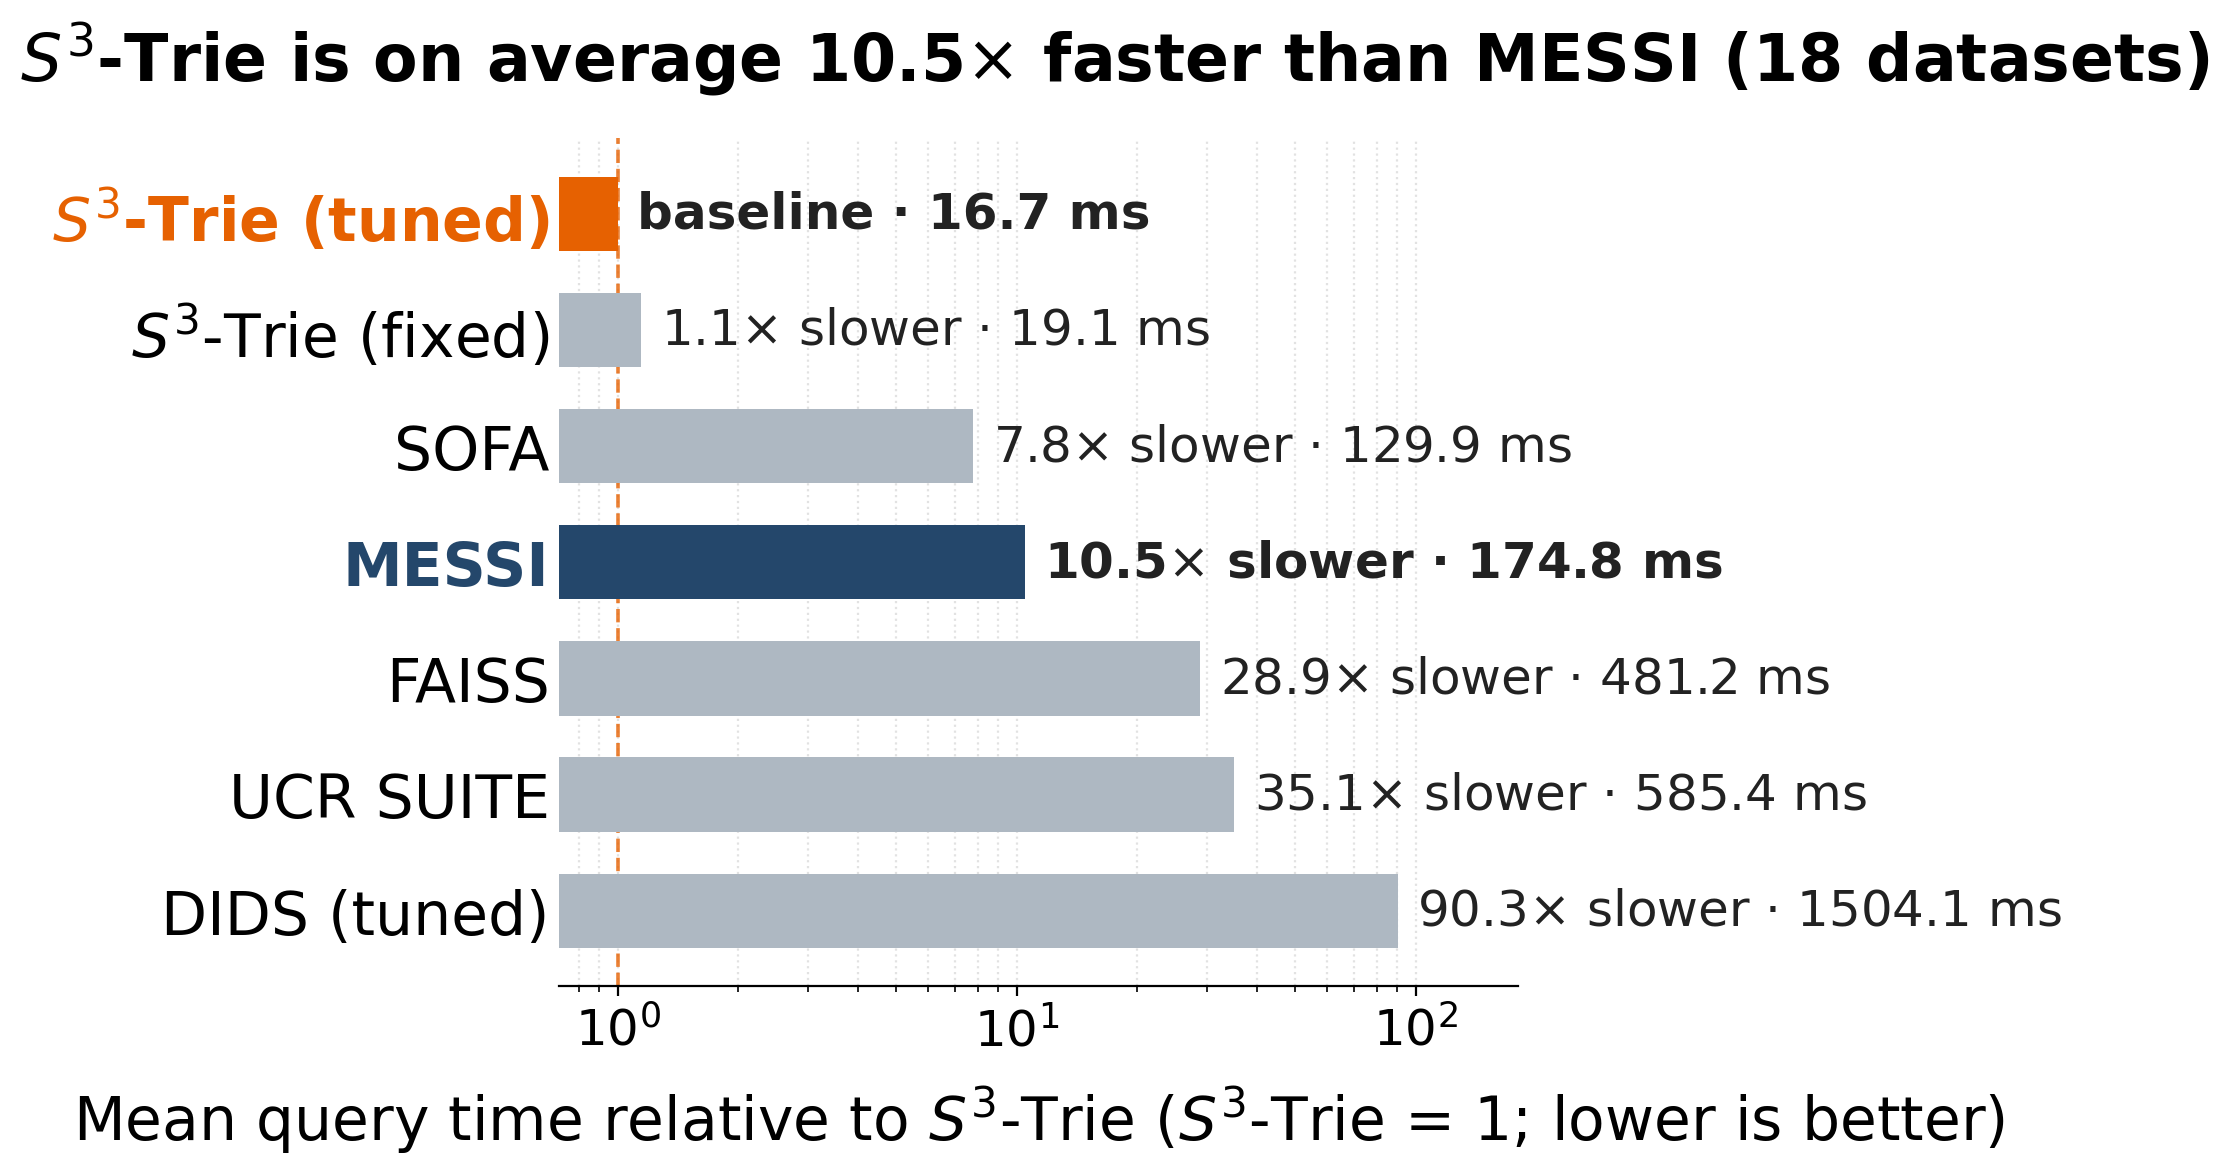

In [6]:
import numpy as np

plot_methods = [
    "$S^3$-Trie (tuned)", "$S^3$-Trie", "MESSI", "SOFA",
    "DIDS (tuned)", "FAISS", "UCR SUITE",
]

def plot_avg_relative_to_s3(methods=plot_methods, datasets=None,
                            common_only=False, output=None, figsize=(8, 6), fontsize_scale=1.0):
    """S3-Trie vs. baselines over all datasets (pooled over all queries).

    Same logic as plot_runtime_relative_to_s3:
      runtime_ms = mean query time of a method over all its query rows
      relative   = runtime_ms / runtime_ms of S3-Trie (tuned)
    common_only=True keeps only datasets where every method has a result,
    so every bar is computed on the same datasets.
    """
    S3_FIXED = r"$S^3$-Trie (fixed)"
    S3_TRIE = r"$S^3$-Trie (tuned)"

    data = subset.loc[subset["Method"].isin(methods)].copy()
    data["Dataset"] = data["Dataset"].str.upper()
    if datasets is not None:
        data = data[data["Dataset"].isin([d.upper() for d in datasets])]

    data["Method"] = data["Method"].replace({
        r"$S^3$-Trie": S3_FIXED,
        r"$S^3$-Trie (tuned)": S3_TRIE,
    })
    if data.empty:
        raise ValueError("No measurements found")

    if common_only:
        has = data.groupby("Dataset")["Method"].nunique()
        data = data[data["Dataset"].isin(has[has == data["Method"].nunique()].index)]

    plot_data = data.groupby("Method", as_index=False).agg(
        runtime_ms=("query time in ms", "mean"),
        n_datasets=("Dataset", "nunique"),
    )

    if S3_TRIE not in plot_data["Method"].values:
        raise ValueError(f"No {S3_TRIE!r} result found")
    if "MESSI" not in plot_data["Method"].values:
        raise ValueError("No MESSI result found")

    s3_time = plot_data.loc[plot_data["Method"] == S3_TRIE, "runtime_ms"].iloc[0]
    plot_data["relative_runtime"] = plot_data["runtime_ms"] / s3_time
    messi_rel = plot_data.loc[plot_data["Method"] == "MESSI", "relative_runtime"].iloc[0]

    plot_data = plot_data.sort_values("relative_runtime").reset_index(drop=True)

    colors = [
        "#e66101" if m == S3_TRIE else "#24476b" if m == "MESSI" else "#aeb8c2"
        for m in plot_data["Method"]
    ]

    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.barh(
        plot_data["Method"], plot_data["relative_runtime"],
        color=colors, height=0.64, edgecolor="none", zorder=2,
    )

    ax.invert_yaxis()
    ax.set_xscale("log")
    ax.set_xlim(plot_data["relative_runtime"].min() / 1.4,
                plot_data["relative_runtime"].max() * 2)

    for bar, row in zip(bars, plot_data.itertuples(index=False)):
        r = row.relative_runtime
        if row.Method == S3_TRIE:
            annotation = rf"baseline · {row.runtime_ms:.1f} ms"
        elif r >= 1:
            annotation = rf"{r:.1f}$\times$ slower · {row.runtime_ms:.1f} ms"
        else:
            annotation = rf"{1/r:.1f}$\times$ faster · {row.runtime_ms:.1f} ms"
        ax.annotate(
            annotation,
            xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
            xytext=(7, 0), textcoords="offset points",
            va="center", ha="left", fontsize=10*fontsize_scale,
            fontweight="bold" if row.Method in (S3_TRIE, "MESSI") else "normal",
            color="#222222",
        )

    ax.axvline(1, color="#e66101", linestyle="--", linewidth=1.3, alpha=0.8, zorder=1)

    n_ds = data["Dataset"].nunique()
    if messi_rel >= 1:
        title = rf"$S^3$-Trie is on average {messi_rel:.1f}$\times$ faster than MESSI ({n_ds} datasets)"
    else:
        title = rf"MESSI is on average {1/messi_rel:.1f}$\times$ faster than $S^3$-Trie ({n_ds} datasets)"
    # ax.set_title(title, fontsize=17*fontsize_scale, fontweight="bold", loc="left", pad=16)
    fig.suptitle(title, fontsize=13*fontsize_scale, fontweight="bold", x=0.0, ha="left")

    ax.set_xlabel(
        r"Mean query time relative to $S^3$-Trie ($S^3$-Trie = 1; lower is better)",
        fontsize=12*fontsize_scale, labelpad=10,
    )
    ax.set_ylabel("")

    ax.grid(axis="x", which="both", linestyle=":", linewidth=0.8,
            color="#999999", alpha=0.28)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelsize=10*fontsize_scale)
    ax.tick_params(axis="y", labelsize=12*fontsize_scale, length=0)
    for label in ax.get_yticklabels():
        if label.get_text() == S3_TRIE:
            label.set(color="#e66101", fontweight="bold")
        elif label.get_text() == "MESSI":
            label.set(color="#24476b", fontweight="bold")

    sns.despine(ax=ax, top=True, right=True, left=True)
    # fig.tight_layout()
    fig.tight_layout(rect=[0, 0, 1, 1.0])


    if output is not None:
        fig.savefig(output, bbox_inches="tight", dpi=300)
    return fig, ax, plot_data


fig, ax, avg_data = plot_avg_relative_to_s3(output="images/avg_relative_to_s3.pdf", figsize=(10, 6), fontsize_scale=1.8)
print(avg_data[["Method", "runtime_ms", "relative_runtime", "n_datasets"]].round(1))
plt.show()


In [7]:
methods = [
    "MESSI", 
    "DIDS (tuned)",     
    "SOFA",
    "FAISS", 
    "UCR SUITE",
    "$S^3$-Trie (tuned)",
    "$S^3$-Trie"
]

# Mean / median runtime over all queries
runtime_stats = (
    subset[subset["Method"].isin(methods)]
    .groupby("Method")["query time in ms"]
    .agg(["mean", "median"])
    # * 1000
)
runtime_stats.columns = ["Mean runtime (ms)", "Median runtime (ms)"]

# Mean runtime per dataset/method
per_dataset = (
    subset[subset["Method"].isin(methods)]
    .groupby(["Dataset", "Method"])["query time in ms"]
    .mean()
    .unstack()
)
per_dataset = per_dataset.reindex(columns=methods)


# Per-dataset speedup relative to MESSI
speedup = per_dataset.copy()
for method in methods:
    speedup[method] = (
        per_dataset["MESSI"] / per_dataset[method]
    )


# Mean speedup across datasets
# geometric mean
mean_speedup = np.exp(np.log(speedup).mean())
# arithmetric mean
# mean_speedup = speedup.mean()

# Final summary table
summary = runtime_stats.copy()
# summary["Per-Dataset Speedup over MESSI"] = mean_speedup
# summary = summary.loc[methods]

display(
    summary.round(1).sort_values(by="Median runtime (ms)")
)

,Mean runtime (ms),Median runtime (ms)
Method,,
$S^3$-Trie (tuned),16.7,4.6
$S^3$-Trie,19.1,6.5
SOFA,129.9,49.7
MESSI,174.8,82.1
DIDS (tuned),1504.1,318.6
FAISS,481.2,395.4
UCR SUITE,585.4,539.2


# Figure 1c: 92.2x Speed-up on OBS (vs. MESSI)

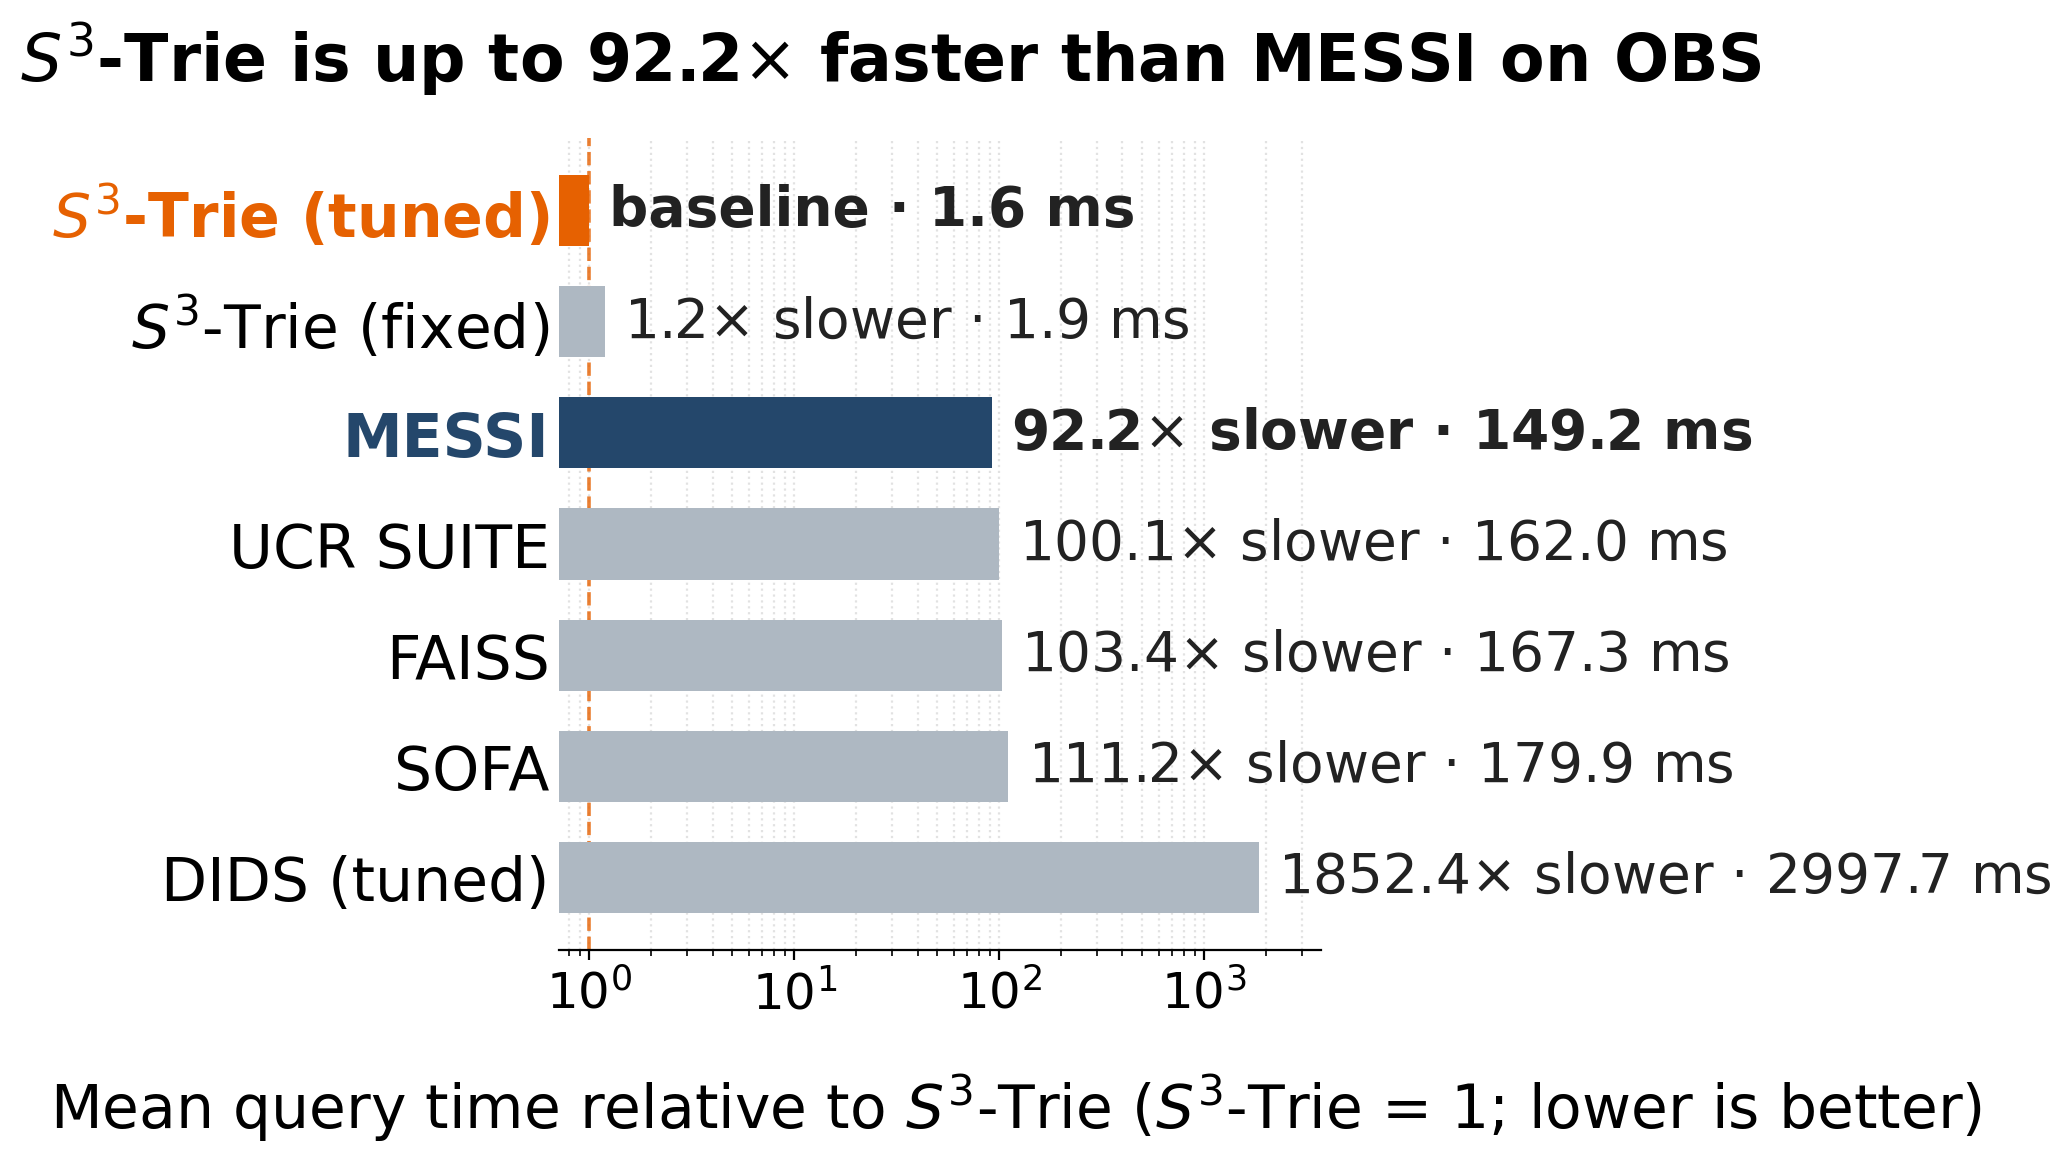

In [8]:

plot_methods = [
    "$S^3$-Trie (tuned)", "$S^3$-Trie", "MESSI", "SOFA", 
    "DIDS (tuned)", "FAISS", "UCR SUITE",
]


def plot_runtime_relative_to_s3(dataset, methods=plot_methods, output=None, figsize=(8, 6), fontsize_scale=1.0):
    # Keep this plot independent of labels reassigned by other cells.
    S3_FIXED = r"$S^3$-Trie (fixed)"
    S3_TRIE = r"$S^3$-Trie (tuned)"
    dataset = dataset.upper()
    
    data = subset.loc[
        (subset["Dataset"].str.upper() == dataset) &
        subset["Method"].isin(methods)
    ].copy()

    data["Method"] = data["Method"].replace({
        r"$S^3$-Trie": S3_FIXED,
        r"$S^3$-Trie (tuned)": S3_TRIE,
    })

    
    if data.empty:
        raise ValueError(f"No measurements found for {dataset!r}")

    plot_data = data.groupby("Method", as_index=False).agg(
        runtime_ms=("query time in ms", "mean")
    )

    if S3_TRIE not in plot_data["Method"].values:
        raise ValueError(f"No {S3_TRIE!r} result found for {dataset!r}")
    if "MESSI" not in plot_data["Method"].values:
        raise ValueError(f"No MESSI result found for {dataset!r}")

    s3_time = plot_data.loc[plot_data["Method"] == S3_TRIE, "runtime_ms"].iloc[0]
    plot_data["relative_runtime"] = plot_data["runtime_ms"] / s3_time
    messi_relative_runtime = plot_data.loc[
        plot_data["Method"] == "MESSI", "relative_runtime"
    ].iloc[0]

    # Fastest at the top; all methods ordered by measured runtime.
    plot_data = plot_data.sort_values(
        "relative_runtime", ascending=True
    ).reset_index(drop=True)

    colors = [
        "#e66101" if m == S3_TRIE else "#24476b" if m == "MESSI" else "#aeb8c2"
        for m in plot_data["Method"]
    ]

    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.barh(
        plot_data["Method"], plot_data["relative_runtime"],
        color=colors, height=0.64, edgecolor="none", zorder=2
    )

    ax.invert_yaxis()
    ax.set_xscale("log")

    minimum = plot_data["relative_runtime"].min()
    maximum = plot_data["relative_runtime"].max()
    ax.set_xlim(minimum / 1.4, maximum * 2)

    for bar, row in zip(bars, plot_data.itertuples(index=False)):
        r = row.relative_runtime

        if row.Method == S3_TRIE:
            annotation = rf"baseline · {row.runtime_ms:.1f} ms"
        elif r >= 1:
            annotation = rf"{r:.1f}$\times$ slower · {row.runtime_ms:.1f} ms"
        else:
            annotation = rf"{1/r:.1f}$\times$ faster · {row.runtime_ms:.1f} ms"

        ax.annotate(
            annotation,
            xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
            xytext=(7, 0), textcoords="offset points",
            va="center", ha="left", fontsize=11*fontsize_scale,
            fontweight="bold" if row.Method in (S3_TRIE, "MESSI") else "normal",
            color="#222222",
        )

    ax.axvline(
        1, color="#e66101", linestyle="--",
        linewidth=1.3, alpha=0.8, zorder=1
    )

    if messi_relative_runtime >= 1:
        title = rf"$S^3$-Trie is up to {messi_relative_runtime:.1f}$\times$ faster than MESSI on {dataset}"
    else:
        title = rf"MESSI is  up to {1/messi_relative_runtime:.1f}$\times$ faster than $S^3$-Trie on {dataset}"

    # ax.set_title(title, fontsize=17*fontsize_scale, fontweight="bold", loc="left", pad=16)
    fig.suptitle(title, fontsize=13*fontsize_scale, fontweight="bold", x=0.0, ha="left")
    ax.set_xlabel(
        r"Mean query time relative to $S^3$-Trie ($S^3$-Trie = 1; lower is better)",
        fontsize=12*fontsize_scale, labelpad=25
    )

    ax.xaxis.set_label_coords(0.6, -0.15)

    ax.set_ylabel("")

    ax.grid(
        axis="x", which="both", linestyle=":",
        linewidth=0.8, color="#999999", alpha=0.28
    )
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelsize=10*fontsize_scale)
    ax.tick_params(axis="y", labelsize=12*fontsize_scale, length=0)

    for label in ax.get_yticklabels():
        if label.get_text() == S3_TRIE:
            label.set(color="#e66101", fontweight="bold")
        elif label.get_text() == "MESSI":
            label.set(color="#24476b", fontweight="bold")

    sns.despine(ax=ax, top=True, right=True, left=True)
    # fig.tight_layout()
    fig.tight_layout(rect=[0, 0, 1, 1.0])

    if output is not None:
        fig.savefig(output, bbox_inches="tight", dpi=300)

    return fig, ax, plot_data


dataset = "OBS"
plot_runtime_relative_to_s3(
    dataset, output=f"images/{dataset}_relative_to_s3_v2.pdf",
    figsize=(10, 6),
    fontsize_scale=1.8,
)
plt.show()

# Figure 8 (Query time and Query time vs. cpu cores)

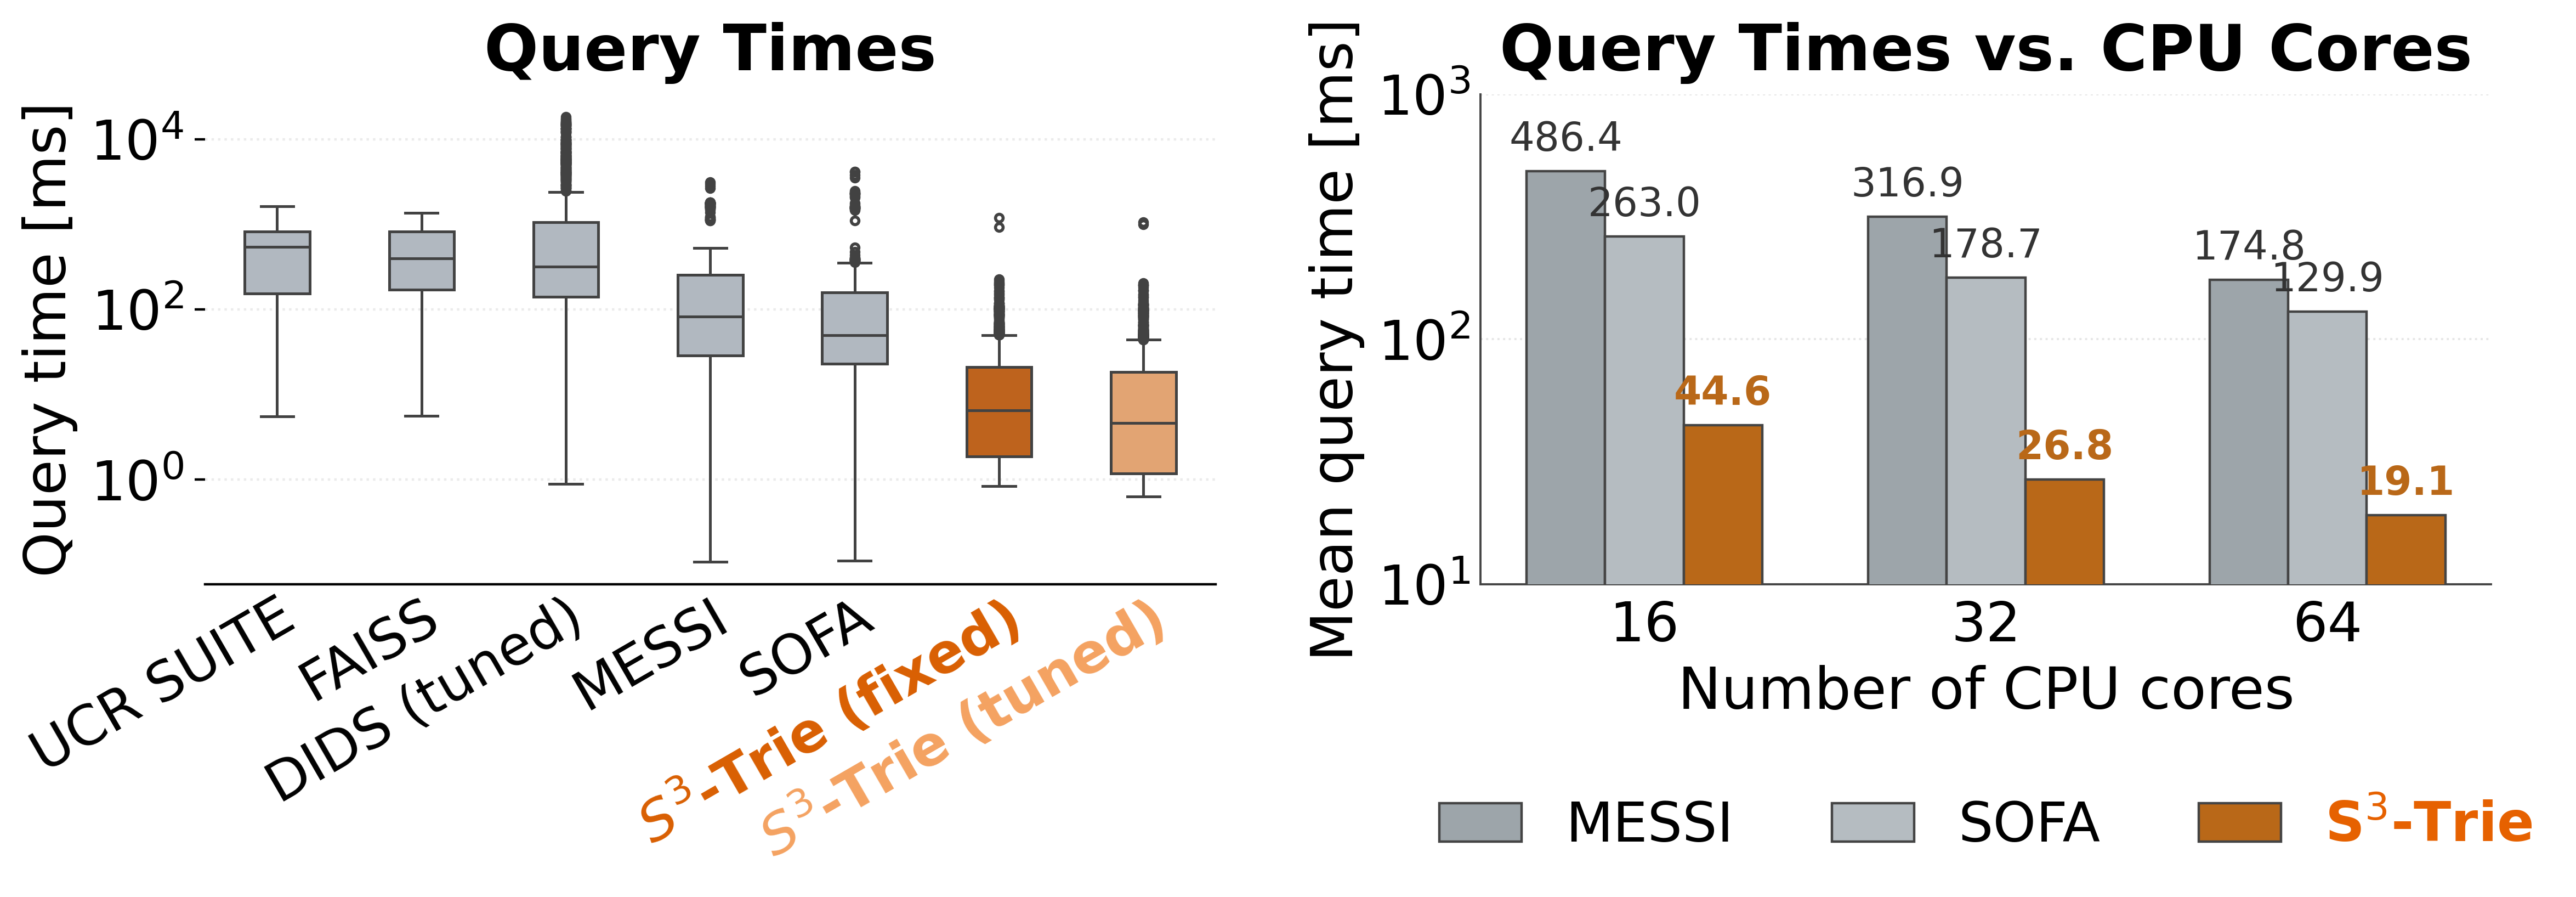

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# Tunable settings (shared by both panels)
# ============================================================
FIG_W, FIG_H   = 12.0, 4.4      # whole figure [inches]
PANEL_WSPACE   = 0.30           # horizontal gap between the panels (fraction of axes width)

TITLE_SIZE     = 21
YLABEL_SIZE    = 19
XLABEL_SIZE    = 19
XTICK_SIZE     = 18
YTICK_SIZE     = 18
LEGEND_SIZE    = 18
ANNOT_SIZE     = 13             # value labels on top of the bars

TITLE_PAD      = 30             # title <-> axes; leaves room for the legend on the right panel
LEGEND_GAP     = 0.2            # legend <-> top of axes
LAYOUT_PAD     = 0.4
PAD_INCHES     = 0.1

# --- left panel: boxplot ---
BOX_WIDTH      = 0.45
BOX_LINEWIDTH  = 0.9
FLIER_SIZE     = 2.5
XTICK_ROTATION = 30
LEFT_TITLE     = "Query Times"

# --- right panel: CPU-core scaling ---
BAR_WIDTH      = 0.23
BAR_LINEWIDTH  = 0.8
RIGHT_TITLE    = "Query Times vs. CPU Cores"

TITLE_PAD      = 8              # legend no longer sits under the title, so the pad can shrink
LEGEND_Y       = -0.34          # legend position below the right axes (axes fraction; more negative = lower)

OUTPUT_PDF     = "images/query_times_combined_v3.pdf"   # None to skip
OUTPUT_PNG     = "images/query_times_combined_v3.png"   # None to skip

# ---------- colors ----------
S3_TRIE  = "$S^3$-Trie (fixed)"
S3_TRIE2 = "$S^3$-Trie (tuned)"
COLOR_FIXED, COLOR_TUNED, COLOR_OTHER = "#d95f02", "#f4a261", "#aeb8c2"

bar_colors = {
    "MESSI": "#9DA5AA",
    "SOFA": "#B5BCC1",
    r"S$^3$-Trie": "#B96818",
}

# ---------- data: right panel (mean query time, ms) ----------
cores = [16, 32, 64]
core_data = {
    "MESSI": [486.4, 316.9, 174.8],
    "SOFA": [263.0, 178.7, 129.9],
    r"S$^3$-Trie": [44.6, 26.8, 19.1],
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------- data: left panel ----------
query_time_plot = subset.copy()
query_time_plot["Method"] = query_time_plot["Method"].replace({"$S^3$-Trie": S3_TRIE})

order = (
    query_time_plot.groupby("Method")["query time in ms"]
    .median()
    .sort_values(ascending=False)
    .index
)
box_colors = {
    m: (COLOR_FIXED if m == S3_TRIE else COLOR_TUNED if m == S3_TRIE2 else COLOR_OTHER)
    for m in order
}

# ============================================================
# Figure
# ============================================================
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(FIG_W, FIG_H), dpi=200)

# ------------------------------------------------------------
# Left panel: boxplot
# ------------------------------------------------------------
sns.boxplot(
    data=query_time_plot,
    x="Method", y="query time in ms",
    order=order, hue="Method", palette=box_colors,
    width=BOX_WIDTH, linewidth=BOX_LINEWIDTH, fliersize=FLIER_SIZE,
    legend=False, ax=ax_l,
)
ax_l.set_yscale("log")
ax_l.set_title(LEFT_TITLE, fontsize=TITLE_SIZE, fontweight="bold", pad=TITLE_PAD)
ax_l.set_xlabel("")
ax_l.set_ylabel("Query time [ms]", fontsize=YLABEL_SIZE)
ax_l.grid(axis="y", which="major", linestyle=":", linewidth=0.8, alpha=0.25)
ax_l.set_axisbelow(True)
ax_l.tick_params(axis="x", length=0, labelsize=XTICK_SIZE, pad=2)
ax_l.tick_params(axis="y", labelsize=YTICK_SIZE)

ax_l.set_xticks(range(len(order)), list(order))
for method, label in zip(order, ax_l.get_xticklabels()):
    label.set_rotation(XTICK_ROTATION)
    label.set_horizontalalignment("right" if XTICK_ROTATION else "center")
    label.set_rotation_mode("anchor")
    if method == S3_TRIE:
        label.set_color(COLOR_FIXED); label.set_fontweight("bold")
    elif method == S3_TRIE2:
        label.set_color(COLOR_TUNED); label.set_fontweight("bold")

sns.despine(ax=ax_l, top=True, right=True, left=True)

# ------------------------------------------------------------
# Right panel: grouped bars over CPU cores
# ------------------------------------------------------------
x = np.arange(len(cores))
for i, (method, values) in enumerate(core_data.items()):
    positions = x + (i - 1) * BAR_WIDTH
    ax_r.bar(
        positions, values, width=BAR_WIDTH,
        color=bar_colors[method], edgecolor="#444444",
        linewidth=BAR_LINEWIDTH, label=method, zorder=3,
    )
    for position, value in zip(positions, values):
        ax_r.annotate(
            f"{value:.1f}", xy=(position, value),
            xytext=(0, 4), textcoords="offset points",
            ha="center", va="bottom", fontsize=ANNOT_SIZE,
            fontweight="bold" if i == 2 else "normal",
            color=bar_colors[method] if i == 2 else "#333333",
        )

ax_r.set_title(RIGHT_TITLE, fontsize=TITLE_SIZE, fontweight="bold", pad=TITLE_PAD)
ax_r.set_xlabel("Number of CPU cores", fontsize=XLABEL_SIZE)
ax_r.set_ylabel("Mean query time [ms]", fontsize=YLABEL_SIZE)
ax_r.set_xticks(x)
ax_r.set_xticklabels(cores)

ax_r.set_yscale("log")
ax_r.set_ylim(10, 1000)
ax_r.set_yticks([10, 100, 1000])
ax_r.set_yticklabels([r"$10^1$", r"$10^2$", r"$10^3$"])

ax_r.set_axisbelow(True)
ax_r.grid(axis="y", which="major", color="#E6E6E6", linestyle=":", linewidth=0.7)
for side in ["top", "right"]:
    ax_r.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax_r.spines[side].set_color("#444444")
    ax_r.spines[side].set_linewidth(0.7)
ax_r.tick_params(axis="x", which="both", length=0, labelsize=XTICK_SIZE, pad=5)
ax_r.tick_params(axis="y", which="both", length=0, labelsize=YTICK_SIZE)

# legend = ax_r.legend(
#     loc="lower center", bbox_to_anchor=(0.5, 1.0), borderaxespad=LEGEND_GAP,
#     ncol=3, frameon=False, fontsize=LEGEND_SIZE,
#     handlelength=1.5, columnspacing=1.8,
# )
legend = ax_r.legend(
    loc="upper center", bbox_to_anchor=(0.5, LEGEND_Y),
    ncol=3, frameon=False, fontsize=LEGEND_SIZE,
    handlelength=1.5, columnspacing=1.8,
)
legend.get_texts()[2].set_color("#E66100")
legend.get_texts()[2].set_fontweight("bold")


# ------------------------------------------------------------
# Layout + save
# ------------------------------------------------------------
fig.tight_layout(pad=LAYOUT_PAD, w_pad=PANEL_WSPACE * 10)

if OUTPUT_PDF is not None:
    fig.savefig(OUTPUT_PDF, bbox_inches="tight", pad_inches=PAD_INCHES)
if OUTPUT_PNG is not None:
    fig.savefig(OUTPUT_PNG, dpi=300, bbox_inches="tight", pad_inches=PAD_INCHES)

plt.show()
